# Week 10 Lab: Machine Learning & Dashboards
**Name:** Mugabo Jason  |  **Student ID:** 29363  |  **Program:** BSc Information Technology (Software Engineering)

Run top to bottom. Put `week10_students.csv` next to this notebook. Every split uses `test_size=0.25, random_state=42`.

## Setup

In [26]:
import pandas as pd, numpy as np
import plotly.express as px
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import mean_absolute_error, r2_score, accuracy_score, confusion_matrix

df = pd.read_csv("week10_students.csv")
df.head()

,student_id,name,gender,program,district,attendance_pct,quiz_avg,assignments_avg,score
0,AUCA001,Aline Uwase,F,Information Systems,Gasabo,55,31.0,35.0,28.6
1,AUCA002,Eric Iradukunda,M,Software Engineering,Musanze,73,61.1,76.7,64.5
2,AUCA003,Diane Uwizeyimana,F,Networking,Muhanga,92,35.2,65.5,52.7
3,AUCA004,Jean Bosco Ikirezi,M,Accounting,Kicukiro,69,65.2,54.2,68.3
4,AUCA005,Patrick Ingabire,M,Information Systems,Huye,88,39.3,42.9,42.3


## Part 1: Explore & Split (5 marks)
### Exercise 1.1: Know your data

In [27]:
print("Shape:", df.shape)
print(df[["quiz_avg", "assignments_avg", "attendance_pct"]].corrwith(df["score"]))

# Most useful feature: the one with the highest correlation with score.
# quiz_avg (and assignments_avg) correlate strongly with score; attendance_pct is weaker,
# because turning up to class does not guarantee understanding.

Shape: (150, 9)
quiz_avg           0.800726
assignments_avg    0.535983
attendance_pct     0.238118
dtype: float64


### Exercise 1.2: Frame & split

In [28]:
features = ["quiz_avg", "assignments_avg", "attendance_pct"]
X = df[features]
y = df["score"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
print("Train:", X_train.shape[0], "| Test:", X_test.shape[0])   # checkpoint: 112 / 38

# Why hide 25%? A model can memorise the data it trained on. Testing on students it has
# never seen shows how it will behave on NEW students, which is the real goal.
# random_state=42 makes the split identical every run.

Train: 112 | Test: 38


## Part 2: Regression, Predict the Score (10 marks)
### Exercise 2.1: Train & read the model

In [29]:
reg = LinearRegression()
reg.fit(X_train, y_train)

for name, coef in zip(features, reg.coef_):
    print(f"{name:18s} {coef:.3f}")
print("Intercept:", round(reg.intercept_, 3))

# One extra quiz point is worth about <coef of quiz_avg> exam points,
# holding assignments and attendance constant. (Read the number printed above.)

quiz_avg           0.579
assignments_avg    0.365
attendance_pct     0.113
Intercept: -4.428


### Exercise 2.2: Judge it honestly (TEST set)

In [30]:
pred = reg.predict(X_test)
mae = mean_absolute_error(y_test, pred)
r2 = r2_score(y_test, pred)
print(f"MAE = {mae:.2f}   R2 = {r2:.2f}")     # checkpoint: MAE ~ 3.3, R2 ~ 0.89

# For a dean:
# MAE: on average our prediction is off by about 3 points out of 100,
#      so a predicted 60 usually means somewhere between 57 and 63.
# R2:  the model explains about 89% of why students' scores differ;
#      the remaining ~11% (effort, luck, health...) it cannot see.

MAE = 3.33   R2 = 0.89


### Exercise 2.3: Predict a new student

In [31]:
new_student = pd.DataFrame({"quiz_avg": [70], "assignments_avg": [75], "attendance_pct": [90]})
print("New student predicted score:", round(reg.predict(new_student)[0], 1))

me = pd.DataFrame({"quiz_avg": [65], "assignments_avg": [70], "attendance_pct": [85]})   # invented numbers
print("My predicted score:", round(reg.predict(me)[0], 1))

New student predicted score: 73.7
My predicted score: 68.4


## Part 3: Classification, Catch the At-Risk Students (8 marks)
### Exercise 3.1: Build the target & train

In [39]:
df["passed"] = (df["score"] >= 50).astype(int)
print(df["passed"].value_counts())

yc = df["passed"]
Xc_train, Xc_test, yc_train, yc_test = train_test_split(X, yc, test_size=0.25, random_state=42)

clf = LogisticRegression(max_iter=1000)
clf.fit(Xc_train, yc_train)

passed
1    131
0     19
Name: count, dtype: int64


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


### Exercise 3.2: The accuracy trap

In [33]:
yc_pred = clf.predict(Xc_test)
print("Model accuracy:", round(accuracy_score(yc_test, yc_pred), 3))
print("Lazy baseline (everyone passes):", round(yc_test.mean(), 3))
cm = confusion_matrix(yc_test, yc_pred)
print("Confusion matrix [[TN FP] [FN TP]]:\n", cm)

# Is the model useless? No. Most students pass, so "predict pass for everyone" already scores
# high, but it catches ZERO failing students (every at-risk student is a false positive).
# The confusion matrix shows our model correctly flags some real failures (top-left cell,
# true negatives), which the lazy model never can. Accuracy hides this because the
# classes are imbalanced; the cost we care about is missing an at-risk student, so we look
# at the matrix, not the single accuracy number.

Model accuracy: 0.895
Lazy baseline (everyone passes): 0.895
Confusion matrix [[TN FP] [FN TP]]:
 [[ 3  1]
 [ 3 31]]


## Part 4: Feature Engineering (5 marks)
### Exercise 4.1: Does more information help?

In [34]:
def eval_r2(X_):
    Xtr, Xte, ytr, yte = train_test_split(X_, y, test_size=0.25, random_state=42)
    m = LinearRegression().fit(Xtr, ytr)
    return r2_score(yte, m.predict(Xte))

X1 = df[["quiz_avg"]]
X2 = df[features]
X3 = pd.concat([df[features], pd.get_dummies(df["program"], dtype=int)], axis=1)

results = pd.DataFrame({
    "version": ["1. quiz_avg only", "2. three numeric features", "3. three + program one-hot"],
    "test_R2": [eval_r2(X1), eval_r2(X2), eval_r2(X3)]
})
print(results.round(2))     # checkpoint: ~0.62 -> 0.89 -> 0.88

# Adding assignments and attendance helped a lot (0.62 -> 0.89): new, relevant signal.
# Adding program did NOT help (0.89 -> ~0.88): it carries almost no extra information,
# and extra columns can even add noise. Lesson: more data is not always better; add
# features that bring NEW information, and always judge on the test set.

                      version  test_R2
0            1. quiz_avg only     0.62
1   2. three numeric features     0.89
2  3. three + program one-hot     0.88


## Part 5: Ship a Dashboard (7 marks)
### Exercise 5.1: The story in three charts

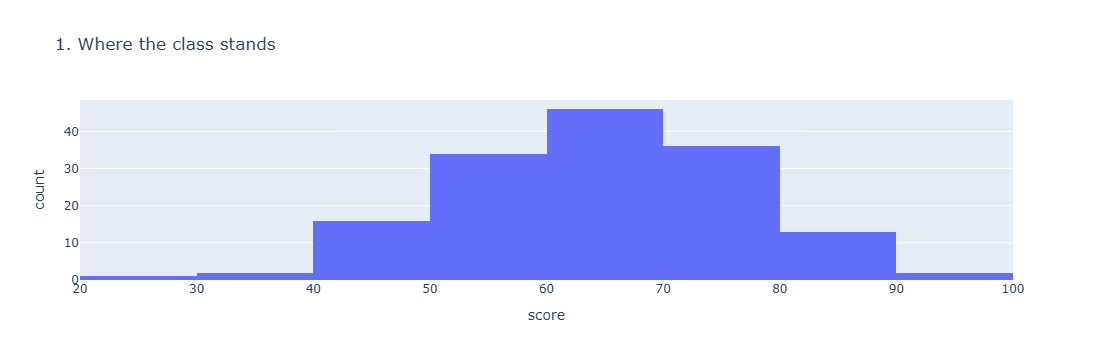

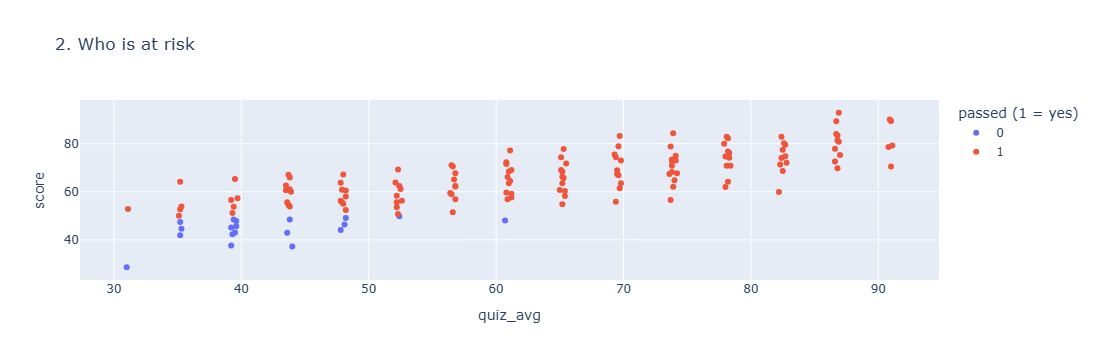

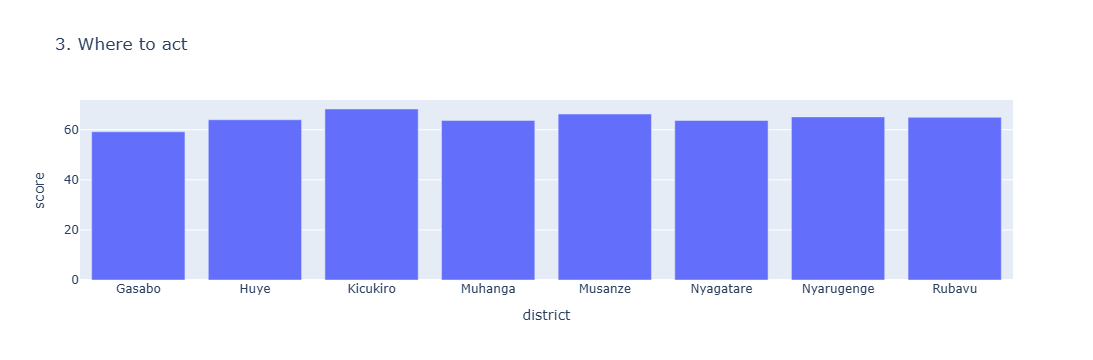

In [35]:
fig1 = px.histogram(df, x="score", nbins=12, title="1. Where the class stands")
fig1.show()

fig2 = px.scatter(df, x="quiz_avg", y="score",
                  color=df["passed"].astype(str),
                  hover_name="name",
                  labels={"color": "passed (1 = yes)"},
                  title="2. Who is at risk")
fig2.show()

district_avg = df.groupby("district", as_index=False)["score"].mean()
fig3 = px.bar(district_avg, x="district", y="score", title="3. Where to act")
fig3.show()

### Exercise 5.2: Publish it

In [36]:
fig2.write_html("class_dashboard.html")
# Open class_dashboard.html in your browser, hover over points, take a screenshot.

### Bonus (+3): One chart, four stories

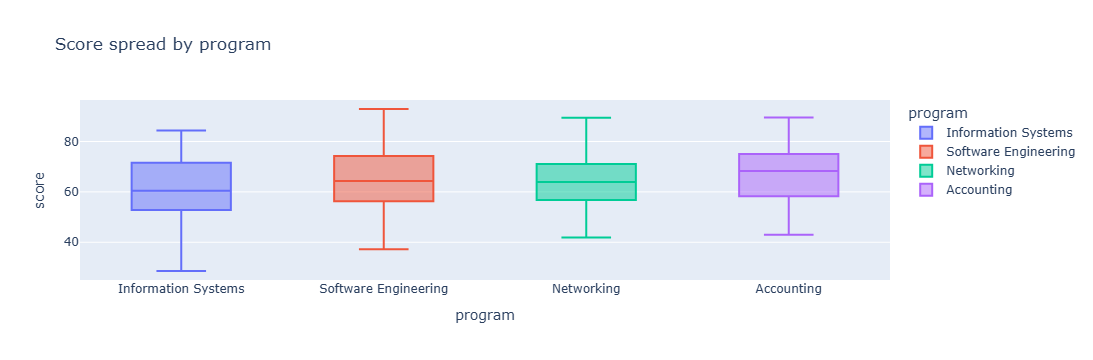

In [37]:
fig4 = px.box(df, x="program", y="score", color="program", title="Score spread by program")
fig4.show()

# Most consistent program = the one with the shortest box (smallest IQR).
# Widest spread = the one with the tallest box / longest whiskers.
# Read both off the chart and name the programs in your two sentences.

## Part 6: Model Card

**1. Purpose.** Predicts a student's final exam score (0-100) from their quiz average, assignments average and attendance. Intended for lecturers and academic advisers to spot students who may need support early.

**2. Data & features.** 150 clean student records. Inputs: `quiz_avg`, `assignments_avg`, `attendance_pct`. Target: `score`. Trained on 112 students, tested on 38 unseen students.

**3. Performance.** On unseen students the average error (MAE) is about 3.3 points, and the model explains about 89% of the differences in scores (R2 ≈ 0.89). In plain words: predictions are usually within a few points, but not exact.

**4. Risks.** A wrong prediction could label a capable student "at risk" (unfair expectations, lost confidence) or miss a student who really needs help. Only 150 students, from one cohort, so it may not fit other years or programs. Use it as an early-warning signal to start a conversation and offer support. Do NOT use it to decide grades, scholarships, admission or discipline, and never without a human reviewing the result.